# Step 7 — Forward stepwise selection
**Owner:** Rishi. **Inputs:** `clean_table.csv` (Steps 1–3), `team_leaders.csv` (Step 4), optional `step6_odds_ratios.csv` (Step 6, for the overlap check).

**Question:** if we could only watch a few sensors, which ones, in what order, and how many are enough?

**How it works:**
1. Start with no sensors.
2. Each round, try adding every remaining candidate; keep the one that lowers the model's error (deviance) the most.
3. Repeat up to 30 sensors → an **entry order**.
4. Choose how many to keep with BIC and with cross-validated deviance (one-SE rule).

**Testing setup (same as Step 6):** Denver's 80/20 split; the 20% test set is locked until the end. Selection is repeated on 50 train/validation splits of the 80% to see which sensors are picked **consistently**.

**Candidates:** only Michael's 295 team leaders (one per group of near-copy sensors), and inside each split only the top 60 by a quick F-test. Searching all subsets of 295 sensors is impossible (2^295 models).

In [1]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from joblib import Parallel, delayed
from sklearn.model_selection import train_test_split, RepeatedStratifiedKFold, StratifiedKFold, cross_val_score
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.feature_selection import f_classif
from sklearn.metrics import log_loss, average_precision_score, roc_auc_score
warnings.filterwarnings("ignore")

SEED = 42
N_REPEATS = 10      # 5-fold x 10 = 50 splits (~5-10 min). Set to 1 for a quick test.
POOL = 60           # candidates per split (top-60 team leaders by F-test)
MAX_SIZE = 30       # stop after 30 sensors

## Load data, Denver's split, Michael's team leaders

In [2]:
clean = pd.read_csv("clean_table.csv")
leaders = pd.read_csv("team_leaders.csv")["sensor"].tolist()
teams = pd.read_csv("sensor_teams.csv").set_index("sensor")

X = clean[leaders]                     # only the 295 team leaders
y = clean["label"]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=SEED)   # identical to Denver's split

print("team leaders used:", len(leaders))
print("train:", X_train.shape, "fails:", y_train.sum(), "| test:", X_test.shape, "fails:", y_test.sum())

team leaders used: 295
train: (1253, 295) fails: 83 | test: (314, 295) fails: 21


## The forward-selection function
* `prep()` = Denver's Step 3 (median fill + scale), fitted on the training part only.
* **Deviance** = 2 × log-loss summed over units. Lower = the model's probabilities fit the real outcomes better.
* **BIC** = deviance + (number of sensors × ln n). Each extra sensor costs ~7 points, so BIC favours small models.
* **CV deviance** = deviance on held-out data (5-fold). It is honest about overfitting, unlike training deviance which always goes down.
* **One-SE size** = the smallest model whose CV deviance is within one standard error of the best one.

In [3]:
def logit():
    return LogisticRegression(penalty=None, max_iter=3000)   # plain logistic, no penalty

def deviance(model, Xs, ys):
    return 2 * log_loss(ys, model.predict_proba(Xs)[:, 1], normalize=False)

def prep_fit(X_part):
    imp = SimpleImputer(strategy="median").fit(X_part)
    sc = StandardScaler().fit(imp.transform(X_part))
    return lambda Z: pd.DataFrame(sc.transform(imp.transform(Z)), columns=Z.columns, index=Z.index)

def forward_select(Xt, yt):
    """Xt is already filled and scaled. Returns the path table and the chosen sizes."""
    F, _ = f_classif(Xt, yt)
    pool = list(Xt.columns[np.argsort(-np.nan_to_num(F))[:POOL]])
    chosen, rows = [], []
    inner = StratifiedKFold(n_splits=5, shuffle=True, random_state=1)
    for step in range(1, MAX_SIZE + 1):
        best = None
        for s in pool:
            if s in chosen:
                continue
            m = logit().fit(Xt[chosen + [s]], yt)
            d = deviance(m, Xt[chosen + [s]], yt)
            if best is None or d < best[1]:
                best = (s, d)
        chosen.append(best[0])
        ll = -cross_val_score(logit(), Xt[chosen], yt, cv=inner, scoring="neg_log_loss")
        cv_dev = 2 * ll * len(yt)                           # held-out deviance, scaled to the full train size so it is comparable with training deviance and BIC
        rows.append({"size": step, "added": best[0], "train_dev": best[1],
                     "bic": best[1] + step * np.log(len(yt)),
                     "cv_dev": cv_dev.mean(), "cv_dev_se": cv_dev.std(ddof=1) / np.sqrt(5)})
    path = pd.DataFrame(rows)
    i = path.cv_dev.idxmin()
    sizes = {"cv_min": int(path.loc[i, "size"]),
             "one_se": int(path.loc[path.cv_dev <= path.cv_dev[i] + path.cv_dev_se[i], "size"].min()),
             "bic": int(path.loc[path.bic.idxmin(), "size"])}
    return path, sizes

## 7.1–7.5 Repeat on 50 train/validation splits
For each split: prepare data → forward selection → keep the one-SE size → score that model on the validation part it never saw. This tells us (a) how stable the picks are and (b) how well the stepwise procedure predicts.

In [4]:
def run_split(k, tr, va):
    warnings.filterwarnings("ignore")
    Xa, ya = X_train.iloc[tr], y_train.iloc[tr]
    Xv, yv = X_train.iloc[va], y_train.iloc[va]
    f = prep_fit(Xa)
    Xa_s, Xv_s = f(Xa), f(Xv)
    path, sizes = forward_select(Xa_s, ya)
    keep = list(path.added[: sizes["one_se"]])
    p = logit().fit(Xa_s[keep], ya).predict_proba(Xv_s[keep])[:, 1]
    path["split"] = k
    path["in_chosen_model"] = path["size"] <= sizes["one_se"]
    score = {"split": k, **{f"size_{a}": b for a, b in sizes.items()},
             "val_pr_auc": average_precision_score(yv, p), "val_roc_auc": roc_auc_score(yv, p)}
    return path, score

cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=N_REPEATS, random_state=SEED)
out = Parallel(n_jobs=-1, verbose=0)(delayed(run_split)(k, tr, va)
                                     for k, (tr, va) in enumerate(cv.split(X_train, y_train)))
paths = pd.concat([o[0] for o in out], ignore_index=True)
scores = pd.DataFrame([o[1] for o in out])
n_splits = len(scores)
paths.to_csv("step7_all_paths.csv", index=False)

print(f"splits run: {n_splits}")
print("chosen size (median over splits):",
      {c: int(scores[c].median()) for c in ["size_one_se", "size_bic", "size_cv_min"]})
print(f"validation PR-AUC: {scores.val_pr_auc.mean():.3f} ± {scores.val_pr_auc.std():.3f} (always-pass ≈ {y_train.mean():.3f})")
print(f"validation ROC-AUC: {scores.val_roc_auc.mean():.3f} ± {scores.val_roc_auc.std():.3f}")

splits run: 50
chosen size (median over splits): {'size_one_se': 7, 'size_bic': 5, 'size_cv_min': 18}
validation PR-AUC: 0.137 ± 0.041 (always-pass ≈ 0.066)
validation ROC-AUC: 0.638 ± 0.067


## 7.5 Selection frequency — which sensors are picked consistently?
Share of the 50 splits in which a sensor made it into the chosen (one-SE) model. Teammates listed so we talk about **teams**, not single sensors.

In [5]:
chosen = paths[paths.in_chosen_model]
freq = (chosen.groupby("added").split.nunique() / n_splits).rename("selection_freq")
entry = paths.groupby("added")["size"].mean().rename("mean_entry_round")
freq_tbl = pd.concat([freq, entry.reindex(freq.index)], axis=1).sort_values("selection_freq", ascending=False)
freq_tbl.index.name = "sensor"
freq_tbl["team_size"] = teams.loc[freq_tbl.index, "team_size"].values
freq_tbl["teammates"] = [", ".join(t for t in teams.index[teams.team == teams.loc[s, "team"]] if t != s)
                         for s in freq_tbl.index]
freq_tbl.to_csv("step7_selection_frequency.csv")
freq_tbl.head(15).round(2)

,selection_freq,mean_entry_round,team_size,teammates
sensor,,,,
Sensor_104,1.00,1.00,1,
Sensor_130,0.72,7.10,1,
Sensor_282,0.52,6.18,1,
Sensor_076,0.36,6.65,1,
Sensor_022,0.32,14.24,1,
Sensor_122,0.32,7.80,1,
Sensor_065,0.30,11.74,1,
Sensor_060,0.28,11.35,1,
Sensor_184,0.26,13.39,3,"Sensor_320, Sensor_456"


## Final run on the whole 80% train set → entry order and size curve

In [6]:
f_all = prep_fit(X_train)
Xtr_s, Xte_s = f_all(X_train), f_all(X_test)
final_path, final_sizes = forward_select(Xtr_s, y_train)
final_path.to_csv("step7_entry_order.csv", index=False)
print("chosen sizes on full train:", final_sizes)
final_path[["size", "added", "train_dev", "bic", "cv_dev"]].head(15).round(1)

chosen sizes on full train: {'cv_min': 17, 'one_se': 7, 'bic': 10}


,size,added,train_dev,bic,cv_dev
0,1,Sensor_104,575.9,583.0,577.9
1,2,Sensor_282,567.2,581.4,571.2
2,3,Sensor_130,556.6,578.0,563.6
3,4,Sensor_122,548.8,577.4,557.0
4,5,Sensor_065,541.6,577.3,553.6
5,6,Sensor_060,535.2,578.0,557.8
6,7,Sensor_574,527.4,577.3,549.4
7,8,Sensor_434,520.3,577.4,545.1
8,9,Sensor_076,513.1,577.3,546.0
9,10,Sensor_064,505.5,576.9,546.1


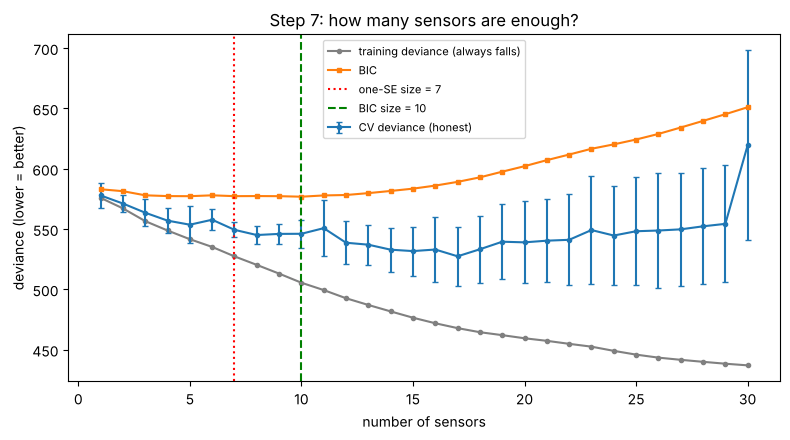

In [7]:
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(final_path["size"], final_path.train_dev, marker=".", c="grey", label="training deviance (always falls)")
ax.errorbar(final_path["size"], final_path.cv_dev, yerr=final_path.cv_dev_se, marker="o", ms=3,
            capsize=2, label="CV deviance (honest)")
ax.plot(final_path["size"], final_path.bic, marker="s", ms=3, label="BIC")
ax.axvline(final_sizes["one_se"], ls=":", c="red", label=f"one-SE size = {final_sizes['one_se']}")
ax.axvline(final_sizes["bic"], ls="--", c="green", label=f"BIC size = {final_sizes['bic']}")
ax.set_xlabel("number of sensors"); ax.set_ylabel("deviance (lower = better)")
ax.set_title("Step 7: how many sensors are enough?"); ax.legend(fontsize=8)
plt.tight_layout(); plt.savefig("step7_size_curve.png", dpi=150); plt.show()

## Check against Step 6 and the locked test set
* Manual's check: **at least 3 of the first 5 stepwise entrants should also be picked by lasso** (Step 6). A lower overlap gets reported, not hidden.
* Test-set score of the final stepwise model (one-SE size). 21 fails → rough numbers.
* **No p-values** are reported for the stepwise model (7.6): the sensors were chosen *because* they looked good, so their p-values are too optimistic.

In [8]:
first5 = list(final_path.added[:5])
try:
    lasso_set = set(pd.read_csv("step6_odds_ratios.csv", index_col=0).index)
    # count a stepwise sensor as a match if lasso picked it or any of its teammates
    def team_of(s): return set(teams.index[teams.team == teams.loc[s, "team"]])
    hits = [s for s in first5 if team_of(s) & lasso_set]
    print(f"first 5 stepwise sensors: {first5}")
    print(f"also picked by lasso (same team counts): {len(hits)} / 5 -> {hits}")
except FileNotFoundError:
    print("Run Step 6 first to get step6_odds_ratios.csv for this check.")

keep = list(final_path.added[: final_sizes["one_se"]])
m = logit().fit(Xtr_s[keep], y_train)
p = m.predict_proba(Xte_s[keep])[:, 1]
print(f"\nfinal stepwise model: {len(keep)} sensors -> {keep}")
print(f"test PR-AUC: {average_precision_score(y_test, p):.3f} (always-pass ≈ {y_test.mean():.3f}) | "
      f"test ROC-AUC: {roc_auc_score(y_test, p):.3f}")

first 5 stepwise sensors: ['Sensor_104', 'Sensor_282', 'Sensor_130', 'Sensor_122', 'Sensor_065']
also picked by lasso (same team counts): 5 / 5 -> ['Sensor_104', 'Sensor_282', 'Sensor_130', 'Sensor_122', 'Sensor_065']

final stepwise model: 7 sensors -> ['Sensor_104', 'Sensor_282', 'Sensor_130', 'Sensor_122', 'Sensor_065', 'Sensor_060', 'Sensor_574']
test PR-AUC: 0.142 (always-pass ≈ 0.067) | test ROC-AUC: 0.682
